In [1]:
# Step 1: Import libraries and load MNIST dataset

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)


In [2]:
# Step 2: Preprocess the dataset

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

validation_size = 5000

x_val = x_train[-validation_size:]
y_val = y_train[-validation_size:]

x_train = x_train[:-validation_size]
y_train = y_train[:-validation_size]

print("Training data:", x_train.shape)
print("Validation data:", x_val.shape)
print("Testing data:", x_test.shape)

Training data: (55000, 28, 28, 1)
Validation data: (5000, 28, 28, 1)
Testing data: (10000, 28, 28, 1)


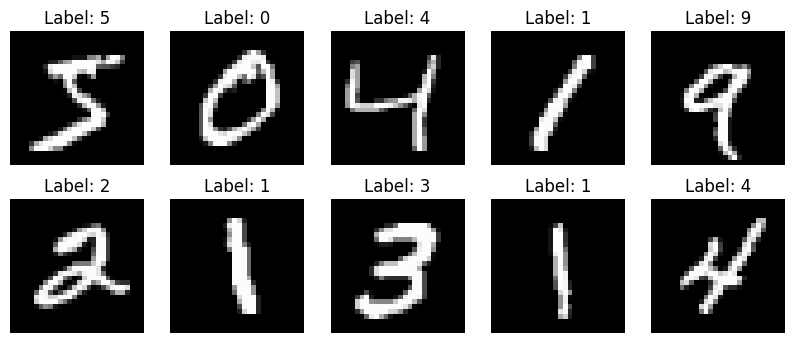

In [3]:
# Step 3: Display sample images

plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].squeeze(), cmap="gray")
    plt.title("Label: " + str(y_train[i]))
    plt.axis("off")

plt.show()

In [4]:
# Step 4: Design the CNN model

model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
# Step 5: Configure the CNN model

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

batch_size = 64
epochs = 5

print("Optimizer: Adam")
print("Learning Rate: 0.001")
print("Batch Size:", batch_size)
print("Epochs:", epochs)

Optimizer: Adam
Learning Rate: 0.001
Batch Size: 64
Epochs: 5


In [6]:
# Step 6: Train the CNN model

history = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    batch_size=batch_size,
    epochs=epochs
)

Epoch 1/5
860/860 ━━━━━━━━━━━━━━━━━━━━ 29s 32ms/step - accuracy: 0.9484 - loss: 0.1731 - val_accuracy: 0.9824 - val_loss: 0.0659
Epoch 2/5
860/860 ━━━━━━━━━━━━━━━━━━━━ 29s 34ms/step - accuracy: 0.9833 - loss: 0.0528 - val_accuracy: 0.9882 - val_loss: 0.0416
Epoch 3/5
860/860 ━━━━━━━━━━━━━━━━━━━━ 39s 31ms/step - accuracy: 0.9890 - loss: 0.0359 - val_accuracy: 0.9876 - val_loss: 0.0414
Epoch 4/5
860/860 ━━━━━━━━━━━━━━━━━━━━ 42s 32ms/step - accuracy: 0.9912 - loss: 0.0274 - val_accuracy: 0.9888 - val_loss: 0.0392
Epoch 5/5
860/860 ━━━━━━━━━━━━━━━━━━━━ 41s 32ms/step - accuracy: 0.9934 - loss: 0.0204 - val_accuracy: 0.9890 - val_loss: 0.0395


In [7]:
# Step 7: Evaluate the model using performance metrics

test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=0
)

y_probability = model.predict(x_test, verbose=0)

y_pred = np.argmax(y_probability, axis=1)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted")
recall = recall_score(y_test, y_pred, average="weighted")
f1 = f1_score(y_test, y_pred, average="weighted")

cm = confusion_matrix(y_test, y_pred)

print("Test Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-Score:", round(f1, 4))

print("\nConfusion Matrix:")
print(cm)

Test Accuracy: 0.99
Precision: 0.99
Recall: 0.99
F1-Score: 0.99

Confusion Matrix:
[[ 974    2    0    0    0    0    3    1    0    0]
 [   0 1133    0    1    0    1    0    0    0    0]
 [   1    1 1018    0    2    0    2    7    1    0]
 [   0    1    1 1001    0    6    0    0    1    0]
 [   0    3    0    0  968    0    1    0    0   10]
 [   2    1    0    5    0  879    1    1    2    1]
 [   2    3    0    0    1    5  946    0    1    0]
 [   0    5    3    1    0    0    0 1014    1    4]
 [   2    1    2    0    0    1    1    1  964    2]
 [   0    0    0    1    1    3    0    1    0 1003]]


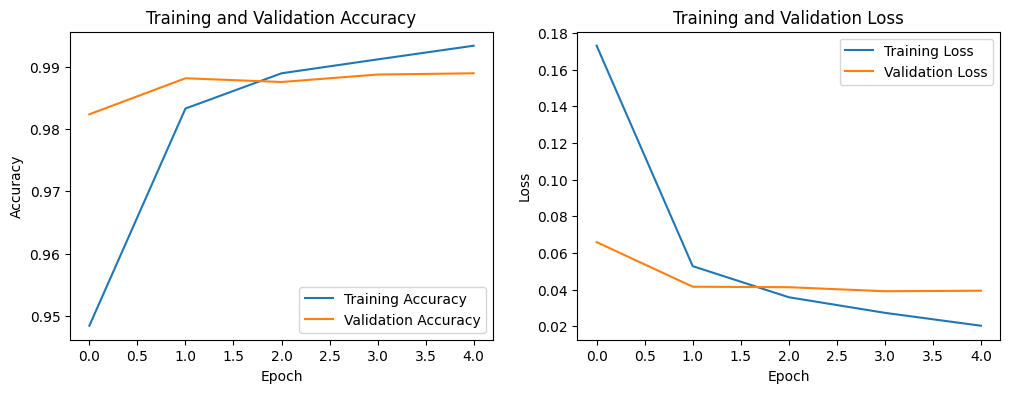

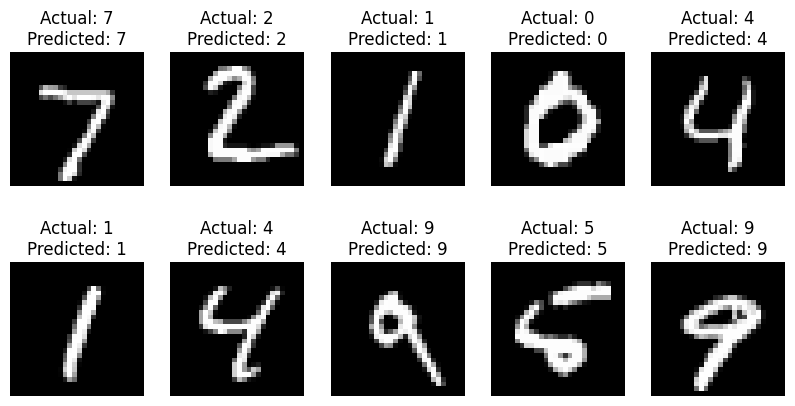

In [8]:
# Step 8: Plot training curves and perform predictions

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap="gray")
    plt.title(
        "Actual: " + str(y_test[i]) +
        "\nPredicted: " + str(y_pred[i])
    )
    plt.axis("off")

plt.show()

Total Misclassified Images: 100


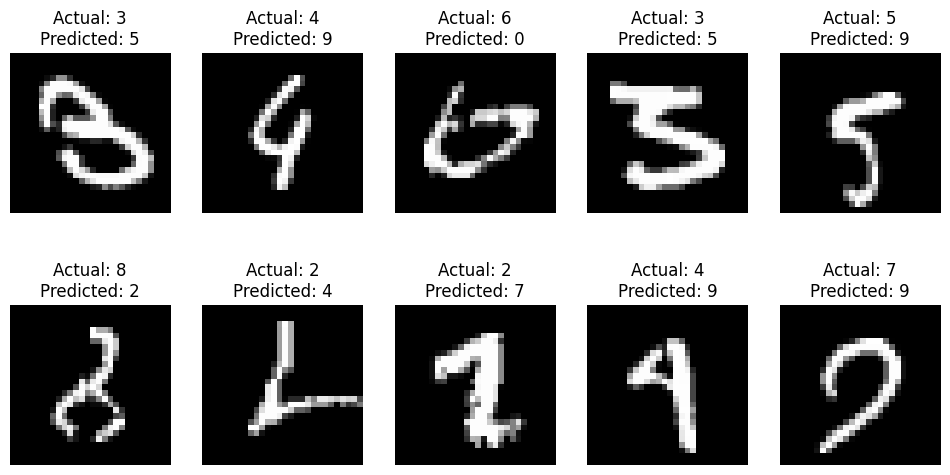

Possible factors affecting accuracy:
1. Similar-looking handwritten digits.
2. Poor image quality.
3. Different writing styles.
4. Insufficient training.
5. Model architecture and hyperparameters.


In [9]:
# Step 9: Analyze misclassified images

misclassified = np.where(y_test != y_pred)[0]

print("Total Misclassified Images:", len(misclassified))

plt.figure(figsize=(12, 6))

for i in range(min(10, len(misclassified))):
    index = misclassified[i]

    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[index].squeeze(), cmap="gray")
    plt.title(
        "Actual: " + str(y_test[index]) +
        "\nPredicted: " + str(y_pred[index])
    )
    plt.axis("off")

plt.show()

print("Possible factors affecting accuracy:")
print("1. Similar-looking handwritten digits.")
print("2. Poor image quality.")
print("3. Different writing styles.")
print("4. Insufficient training.")
print("5. Model architecture and hyperparameters.")

In [10]:
# Step 10: Summarize results and applications

print("Observations:")
print("1. MNIST dataset was successfully used for image classification.")
print("2. Images were normalized and divided into training, validation and testing sets.")
print("3. A CNN was designed using convolution, pooling and fully connected layers.")
print("4. The model was trained using the Adam optimizer.")
print("5. Accuracy, Precision, Recall, F1-Score and Confusion Matrix were calculated.")
print("6. The trained CNN successfully classified unseen handwritten digits.")
print("7. CNN-based image classification is useful in OCR, medical imaging,")
print("   facial recognition, handwriting recognition and industrial inspection.")

Observations:
1. MNIST dataset was successfully used for image classification.
2. Images were normalized and divided into training, validation and testing sets.
3. A CNN was designed using convolution, pooling and fully connected layers.
4. The model was trained using the Adam optimizer.
5. Accuracy, Precision, Recall, F1-Score and Confusion Matrix were calculated.
6. The trained CNN successfully classified unseen handwritten digits.
7. CNN-based image classification is useful in OCR, medical imaging,
   facial recognition, handwriting recognition and industrial inspection.
